In [1]:
from unbiased_mcmc import *

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


In [ ]:
import numpy as np 
def log_target0(x):
    return -0.5 * np.sum(x**2, axis=-1)

def log_target1(x, D):
    return -0.5 * np.sum((x - D)**2, axis=-1)


def g_log_target(x, path, D):
    return (1 - path) * log_target0(x) + path * log_target1(x, D)


def g_grad_log_target(x, D):
    return log_target1(x, D) - log_target0(x)

In [3]:
L = 10  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L # uniform grid of lambda values in [0, 1]

In [15]:

d = 2
Sigma = np.eye(d) # covaraince of the proposal of RWMH
mean_init = np.array([-2.0] * d) # mean for the initial distribution of MH
Sigma_init = np.eye(d) # covariance of the initial ditribution of MH
cholesky_Sigma = cholesky(Sigma)
inv_cholesky_Sigma = inv_cholesky(Sigma)


alpha = 2 #  scale 
D = alpha * np.array([1.0] * d)  # mean shift of the target distribution

log_target_path = lambda x, path: g_log_target(x, path, D)
grad_log_target_path = lambda x, path: g_grad_log_target(x, D)

In [16]:
mk_grid = tune_km_grid(
    lambda_grid,
    mean_init,
    Sigma_init,
    Sigma,
    cholesky_Sigma,
    inv_cholesky_Sigma,
    log_target_path,
    lag=1,
    nrep=1000,
)

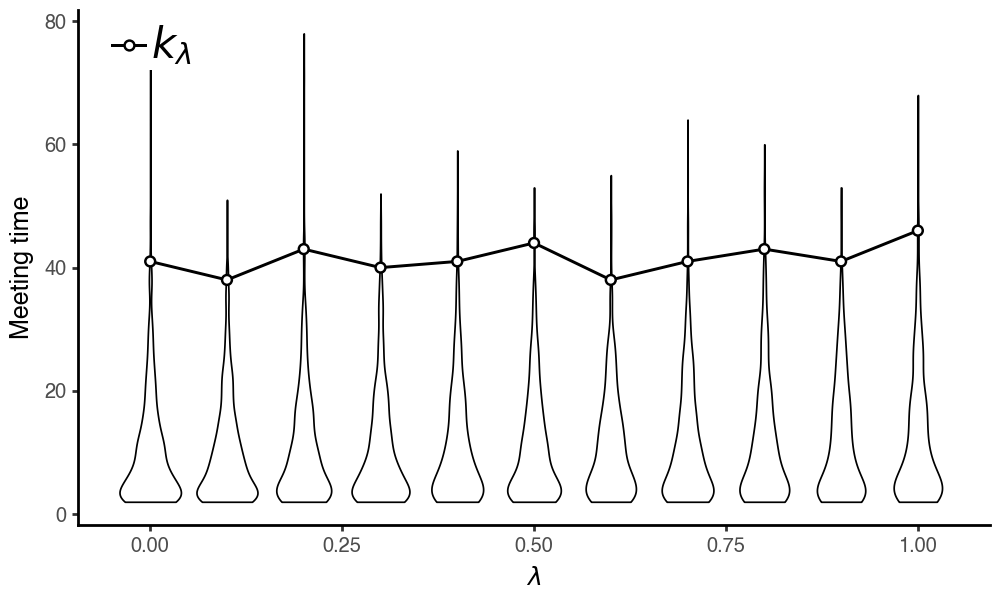

In [17]:
plot_km_grid(mk_grid, lambda_grid)

In [18]:
k_grid = mk_grid["k_grid"]
m_grid = mk_grid["m_grid"]
lag = k_grid

In [20]:
moment_results = estimate_moments(
        lambda_grid,
        k_grid,
        m_grid,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_Sigma,
        inv_cholesky_Sigma,
        log_target_path,
        grad_log_target_path,
        lag=1,
        nrep=1000,
    )

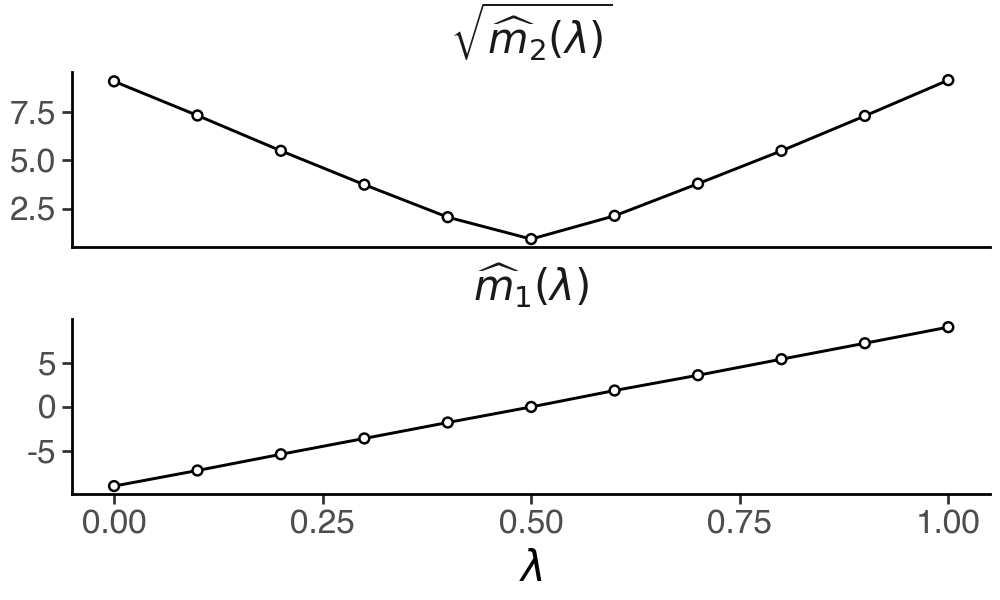

In [ ]:
plot_m1_m2(moment_results, lambda_grid)

In [21]:
m2 = moment_results["m2"] # to define the optimal proposal for UPS

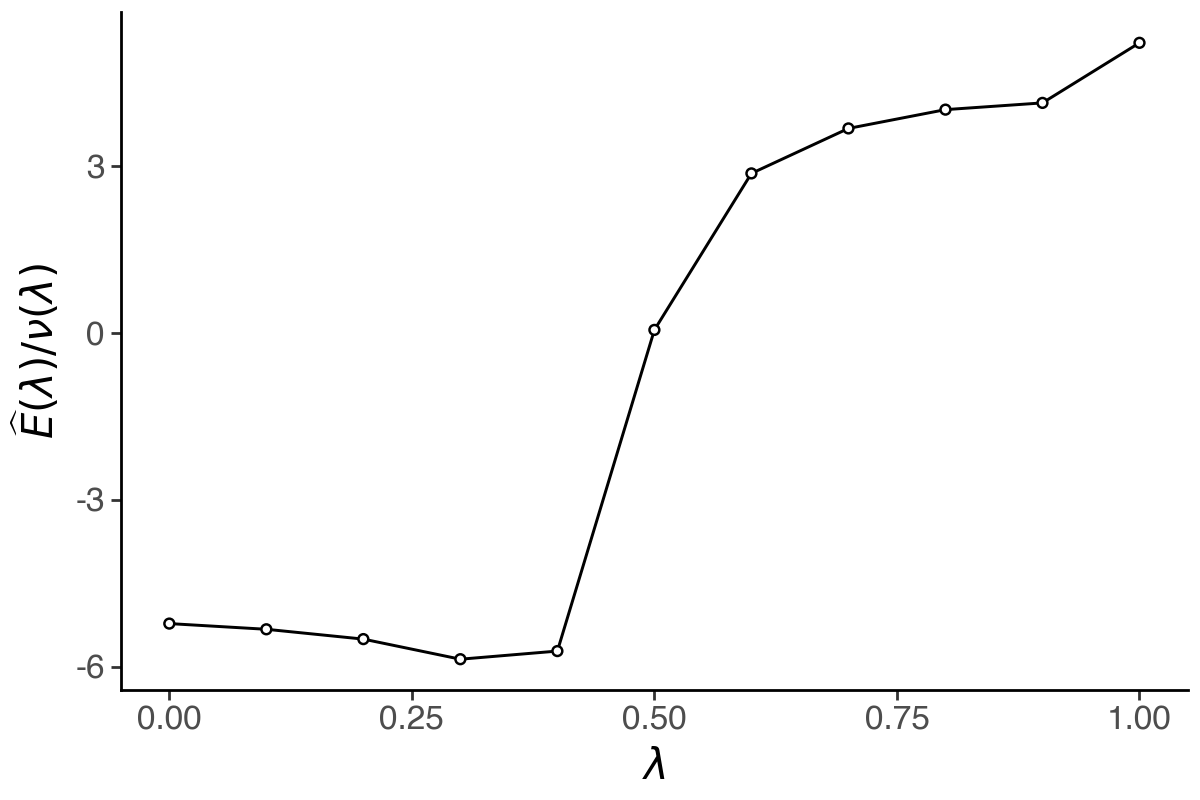

In [ ]:
plot_E_lambda_over_q(
	lambda_grid,
	m2,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	nrep=1000,
)

In [22]:
N_pilot = 1000
sigma = estimate_sigma(lambda_grid, k_grid, m_grid, lag, mean_init, Sigma_init, Sigma, cholesky_Sigma, inv_cholesky_Sigma, log_target_path, grad_log_target_path, N_pilot)

In [ ]:
compare_estimators(
	lambda_grid,
	m2,
	sigma,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	log_target0,
	log_target1,
    D,
	d,
	M=100,
	nrep=1000,
	true_value=0.0,
	n_workers=14,
)

UPS:  11%|█         | 112/1000 [03:50<30:28,  2.06s/it]


IS prefixes (max M=245656): 100%|██████████| 10/10 [00:00<00:00, 168.43it/s]
/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


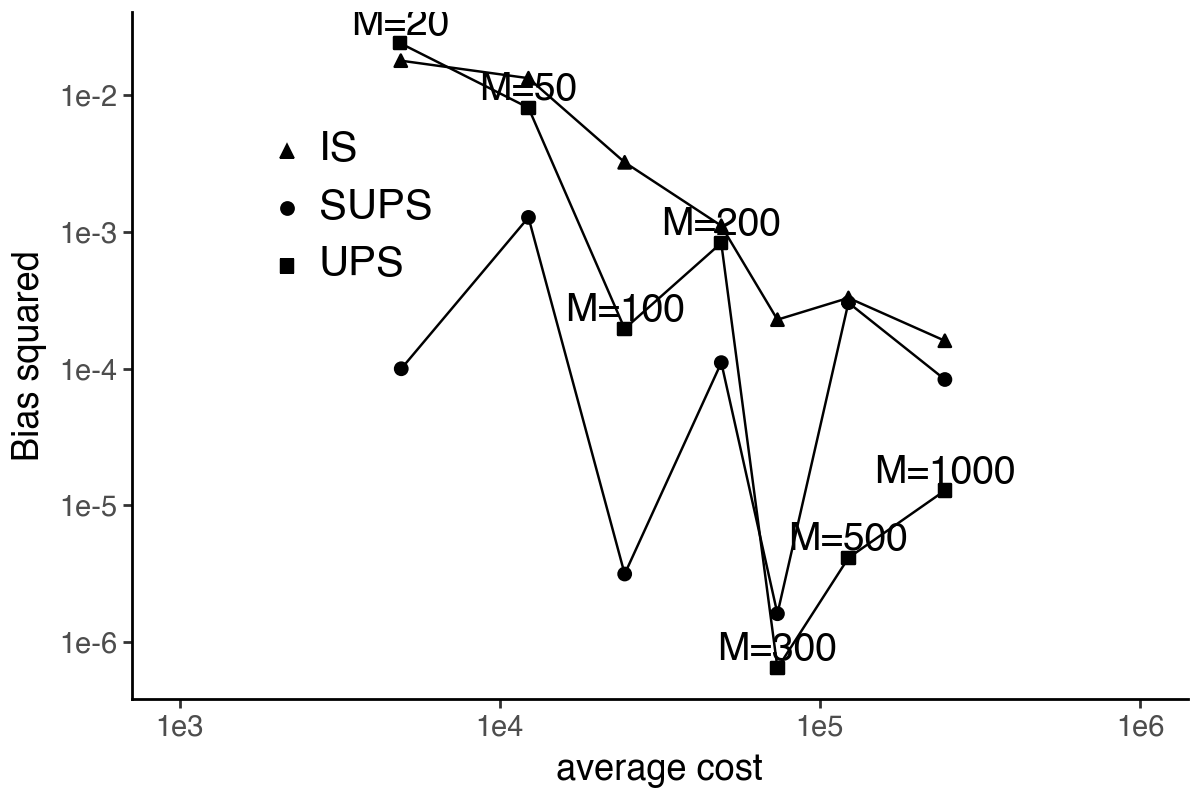

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


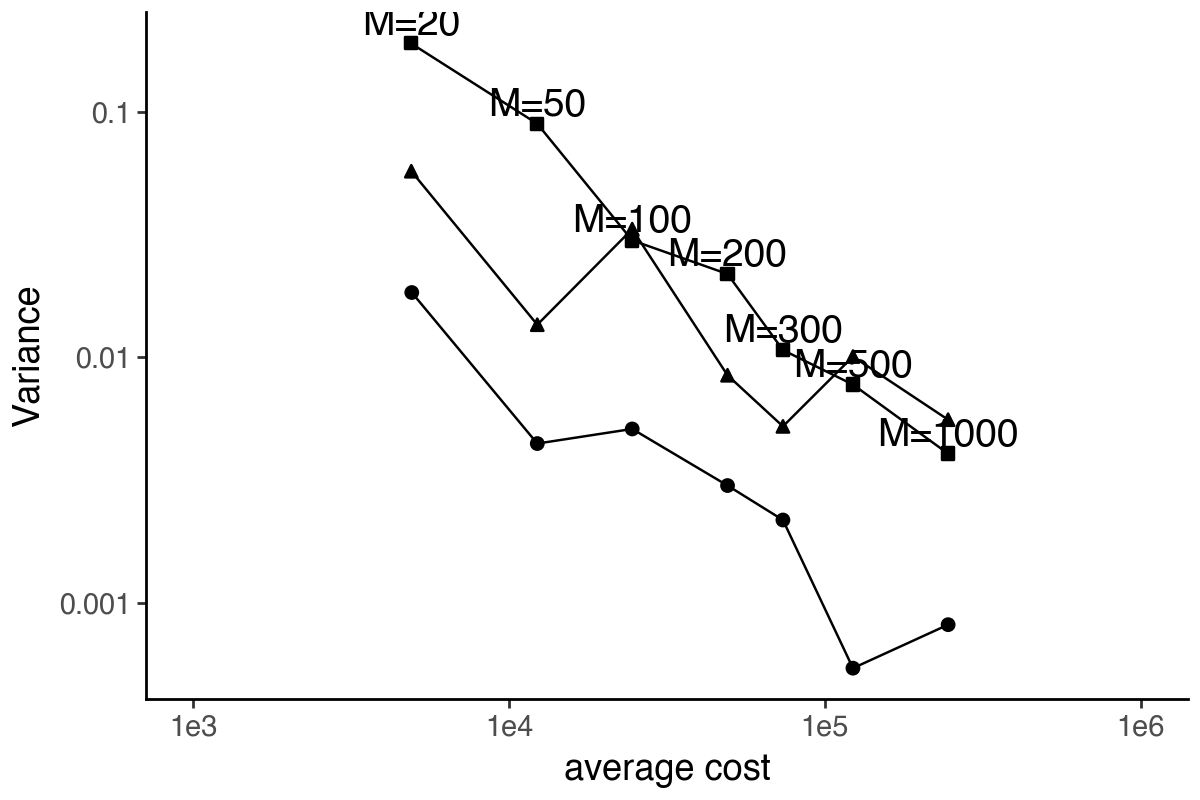

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


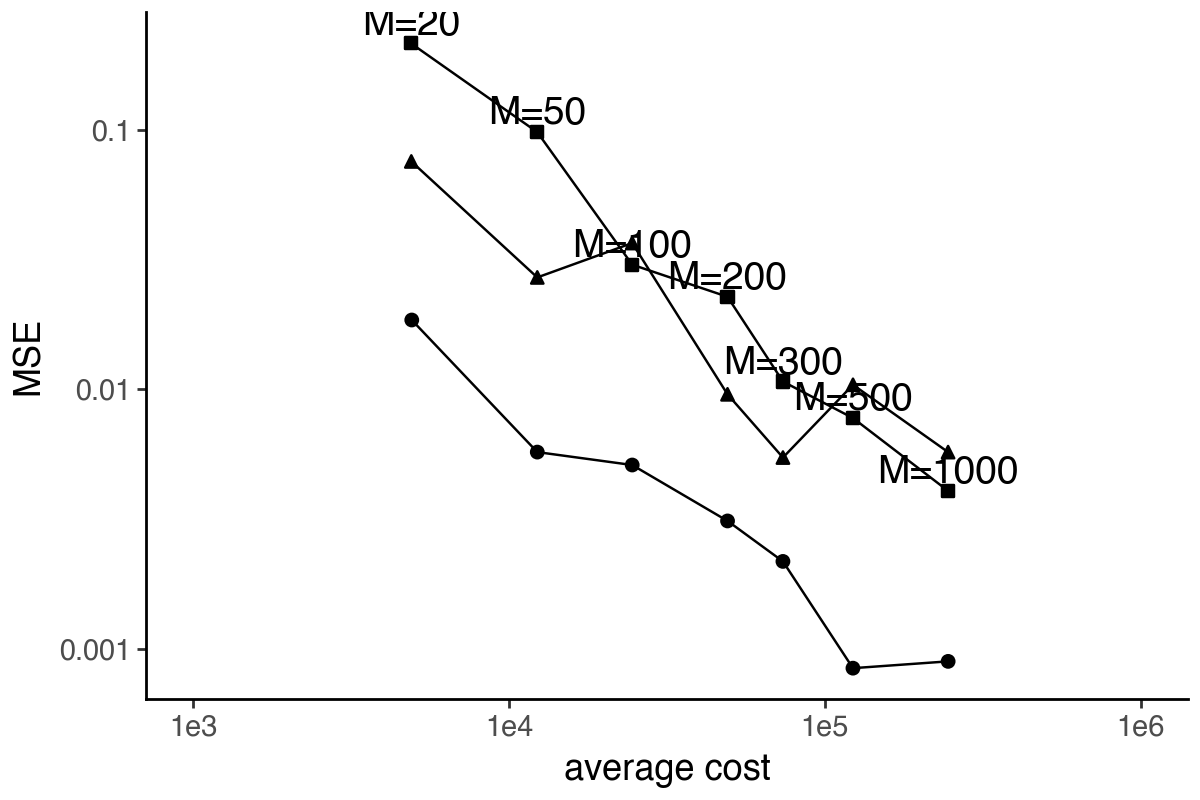

{'data':        M Estimator      Cost  Bias squared  Variance       MSE    M_is
 0     20       UPS    4887.9  2.410118e-02  0.190794  0.214896    4905
 1     20      SUPS    4921.3  9.966305e-05  0.018389  0.018489    4905
 2     20        IS    4905.0  1.796845e-02  0.057406  0.075375    4905
 3     50       UPS   12288.1  8.121925e-03  0.089620  0.097742   12289
 4     50      SUPS   12289.6  1.278680e-03  0.004456  0.005734   12289
 5     50        IS   12289.0  1.337062e-02  0.013594  0.026965   12289
 6    100       UPS   24547.6  1.957961e-04  0.029998  0.030194   24551
 7    100      SUPS   24553.7  3.129537e-06  0.005111  0.005114   24551
 8    100        IS   24551.0  3.235994e-03  0.033330  0.036566   24551
 9    200       UPS   49182.4  8.311837e-04  0.021887  0.022718   49192
 10   200      SUPS   49202.2  1.104740e-04  0.003004  0.003115   49192
 11   200        IS   49192.0  1.110764e-03  0.008458  0.009569   49192
 12   300       UPS   73697.6  6.396855e-07  0.010714  0

In [23]:
import importlib

normal_plots = importlib.import_module("unbiased_mcmc.normal_plots")
normal_plots = importlib.reload(normal_plots)
compare_estimators_mse_by_budget = normal_plots.compare_estimators_mse_by_budget

compare_estimators_mse_by_budget(
	lambda_grid,
	m2,
	sigma,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	log_target0,
	log_target1,
	D,
	d,
	M_values=(20, 50, 100, 200, 300, 500, 1000),
	nrep=10,
	true_value=0.0,
	n_workers=14,
)